# Parent-feature weight

**How much parent attributes influence clustering compared with child attributes. Higher values emphasize the parent when creating groups.**

**First prerequisite:** prepare the account sample, then complete [01_baseline.ipynb](../01_baseline.ipynb). No historical experiment runs or original model checkpoints are used here.

**Work required:** Changed values require clustering, diffusion, classifier training, and generation.

The generator's guidance classifiers predict parent groups. The separate overdraft evaluator stays fixed. You run this notebook yourself.

[Instructions and index](../../README.md) · [Final comparison](../02_all_experiments.ipynb) · [Research log](../../docs/PROGRESS.md)

In [6]:
import os
import sys
from pathlib import Path

import pandas as pd
import yaml
from IPython.display import Image
from IPython.display import display as show


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/transaction-evaluation-matplotlib")
MULTI_TABLE = ROOT / "implementations/tabular_data/multi_table"

from implementations.tabular_data.multi_table.evaluation.transaction_evaluation import evaluate_saved_runs
from implementations.tabular_data.multi_table.experiments.dataset_settings import DATA_DIR as DEFAULT_DATA_DIR
from implementations.tabular_data.multi_table.experiments.tuning import (
    DEFAULT_EXPERIMENT_ROOT,
    DEFAULT_REPORT_ROOT,
    PRESETS,
    base_config,
    completed_runs,
    make_trials,
    preview_trials,
    run_trials,
)


## 1. Settings — keep the baseline fixed

Use the `.venv` kernel. Start with one training/sampling seed and a short candidate list. Keep `RUN_NEW_TRIALS = False` to preview or evaluate completed results. Enable it yourself on a GPU to run a sweep.

The baseline parameter value is included automatically even if you narrow `VALUES`; duplicates are removed. All other settings match the baseline notebook. Keep its input data, root, full sample scale, and base settings fixed. Candidate values are starting experiments, not proven optimal choices.

In [7]:
EXPERIMENT = "parent_weight"
RUN_NEW_TRIALS = False
SAMPLING_SEEDS = [42]
TRAINING_SEEDS = [42, 43, 44]
# Edit dataset_settings.py once to switch every notebook, or override here.
DATA_DIR = DEFAULT_DATA_DIR
EXPERIMENT_ROOT = DEFAULT_EXPERIMENT_ROOT
OUTPUT_ROOT = DEFAULT_REPORT_ROOT
BASE = base_config(fresh_training=True)
PARAMETER, DEFAULT_VALUES = PRESETS[EXPERIMENT]
VALUES = list(DEFAULT_VALUES)  # Narrow this list for the first sweep.

print(f"Selected processed dataset: {DATA_DIR}")


Selected processed dataset: /home/armoso/repo/vector-bootcamp-synthetic-data/implementations/tabular_data/multi_table/data/berka_accounts_500_seed42


## 2. Preview and check the baseline

This creates no models or synthetic data. Stage IDs show logical reuse groups; completed stages are checked during execution. A model set covers all nine parent/table relations.

The baseline is included for each requested seed pair. Vary sampling seeds later to test generation variability; vary training seeds separately to test model variability.

In [8]:
TRIALS = make_trials(
    BASE, PARAMETER, VALUES, sampling_seeds=SAMPLING_SEEDS,
    training_seeds=TRAINING_SEEDS, include_baseline=True,
)
PLAN = preview_trials(TRIALS)
show(PLAN.drop(columns="config"))
COUNTS = PLAN[["cluster", "diffusion", "model", "sample"]].nunique()
print(f"Planned configurations/generations: {COUNTS['sample']} (includes the baseline).")
print(f"Logical sets before cache lookup: {COUNTS['cluster']} clustering, "
      f"{COUNTS['diffusion']} diffusion, {COUNTS['model']} classifier.")
BASELINE_DIRS = completed_runs(DATA_DIR, EXPERIMENT_ROOT, configs=[BASE]) if DATA_DIR.is_dir() else []
if BASELINE_DIRS:
    print("Baseline found. Matching completed stages will be reused.")
else:
    print("No completed baseline yet. Run 01_baseline.ipynb before enabling this sweep.")


,cluster,diffusion,model,sample,training_seed,sampling_seed,guidance,clusters
0,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,013d0db4bc897faae5dc,42,42,1.0,50
1,f86b14712a47d888e771,971b58567fd64e2505c9,b9a95c773272186c83fb,f3bbc134d3e6c15f88b9,42,42,1.0,50
2,1692bf774bb46ac69451,8ee13f9e20f327aa1f1a,32423fc0c034cec39457,f2b9e2f45df2db6e2253,42,42,1.0,50
3,9bff39262da3114e3378,96e9747e34fe0dab855d,c7e37726fa93ff6db7fe,a1548bd6458955ff420a,43,42,1.0,50
4,ae918a2ad8a39121cce1,339cc7519e80b9070acd,1e276fc1924289685028,045200337899fd52d3f7,43,42,1.0,50
5,7e77bf6ae72d116b0259,a43b71d7466846b95e4e,83823d9e049753307197,b373cecca5b07f6d35a3,43,42,1.0,50
6,8f89b1c222c3a39b687e,20bd03f27b55955b0fc4,f32b015badb3c8e25f3a,e418a2c6497aacdab373,44,42,1.0,50
7,2e55fde49a4101e49258,3892a279ad7768d83d4a,7efe1eb1a3a17d70d140,02f96d6ff18fa80a6a9c,44,42,1.0,50
8,89bb2576c4beb0fa3cbe,8856760462d2a3d91f99,5389860bdf613e081cac,98a15cbccb0870fe7d3e,44,42,1.0,50


Planned configurations/generations: 9 (includes the baseline).
Logical sets before cache lookup: 9 clustering, 9 diffusion, 9 classifier.
Baseline found. Matching completed stages will be reused.


## 3. Run this sweep on GPU

This step requires the completed baseline and your `RUN_NEW_TRIALS = True` setting. Compatible baseline stages are reused. Run one generating notebook at a time; retain the same experiment root across notebooks. Inspect `status.json` if a stage fails before choosing a fresh root to retry.

In [9]:
NEW_RUN_DIRS = []
if RUN_NEW_TRIALS:
    if not BASELINE_DIRS:
        raise ValueError("Create the reference run in 01_baseline.ipynb before starting this sweep.")
    EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)
    PLAN.drop(columns="config").to_csv(EXPERIMENT_ROOT / f"plan_{EXPERIMENT}.csv", index=False)
    NEW_RUN_DIRS = run_trials(TRIALS, DATA_DIR, EXPERIMENT_ROOT, device="cuda")
    show(pd.DataFrame({"saved_run": [str(path) for path in NEW_RUN_DIRS]}))
else:
    print("Preview only. Enable RUN_NEW_TRIALS yourself after completing the baseline.")


Preview only. Enable RUN_NEW_TRIALS yourself after completing the baseline.


## 4. Evaluate completed results on CPU

A single real-trained overdraft detector evaluates the baseline and completed variants in this call. An early preview may show just the baseline; incomplete sweeps are not presented as complete comparisons.

Compare event counts, AP/prevalence/uncertainty, overall and overdraft-only distributions, account integrity, and chronology. A high raw synthetic AP alone does not establish the best data.

The same report also scores all 8 tables and 8 parent/child edges: column distributions, missing/unknown values, within/cross-table relationships, cardinalities, and PK/FK integrity. It checks client/account combinations through `disp`. The full-table and overdraft score groups remain separate; no combined winner score is used.

Evaluating 2d76585ca21ab3ca4c6c
Evaluating 524edfcd0e6f14a9c5b2
Evaluating 6e847ecb01ac2ee8baa2
Evaluating 7b6d338840bcf62afbdd
Evaluating 884369e84f4bb210a49a
Evaluating a0f0a8c156f32ab5d214
Evaluating bae6ba87788b89f05709
Evaluating e2cf71fc9b2cb2bdcc74
Evaluating fa627eaf5227b73e6be4


,parameter_value,average_precision,average_precision_low,average_precision_high,standardized_ap,overdraft_prevalence,transaction_ks,transaction_tvd,overdraft_numerical_ks,synthetic_transaction_before_account_rate
dataset,,,,,,,,,,
real_test,NaN,0.2422,0.0005,0.3606,0.2422,0.0017,NaN,NaN,NaN,NaN
2d76585ca21ab3ca4c6c,2.0,0.0178,0.0160,0.0197,0.0054,0.0055,0.0505,0.0244,0.7130,0.2265
524edfcd0e6f14a9c5b2,1.0,0.0063,0.0053,0.0076,0.0036,0.0029,0.0612,0.0281,0.4948,0.1606
6e847ecb01ac2ee8baa2,2.0,0.0036,0.0030,0.0046,0.0025,0.0024,0.0506,0.0267,0.2977,0.1525
7b6d338840bcf62afbdd,0.5,0.0074,0.0061,0.0092,0.0037,0.0033,0.0573,0.0205,0.4141,0.2168
884369e84f4bb210a49a,2.0,0.0086,0.0070,0.0134,0.0035,0.0042,0.0616,0.0205,0.3437,0.1984
a0f0a8c156f32ab5d214,0.5,0.0027,0.0021,0.0041,0.0027,0.0017,0.0534,0.0291,0.2355,0.2462
bae6ba87788b89f05709,0.5,0.0154,0.0143,0.0167,0.0050,0.0052,0.0498,0.0232,0.6635,0.2248
e2cf71fc9b2cb2bdcc74,1.0,0.0161,0.0144,0.0183,0.0056,0.0048,0.0560,0.0229,0.7073,0.2052


Detailed report: /home/armoso/repo/vector-bootcamp-synthetic-data/implementations/tabular_data/multi_table/results/experiments/transaction_overdraft_from_scratch/b52d0d6409bd1389


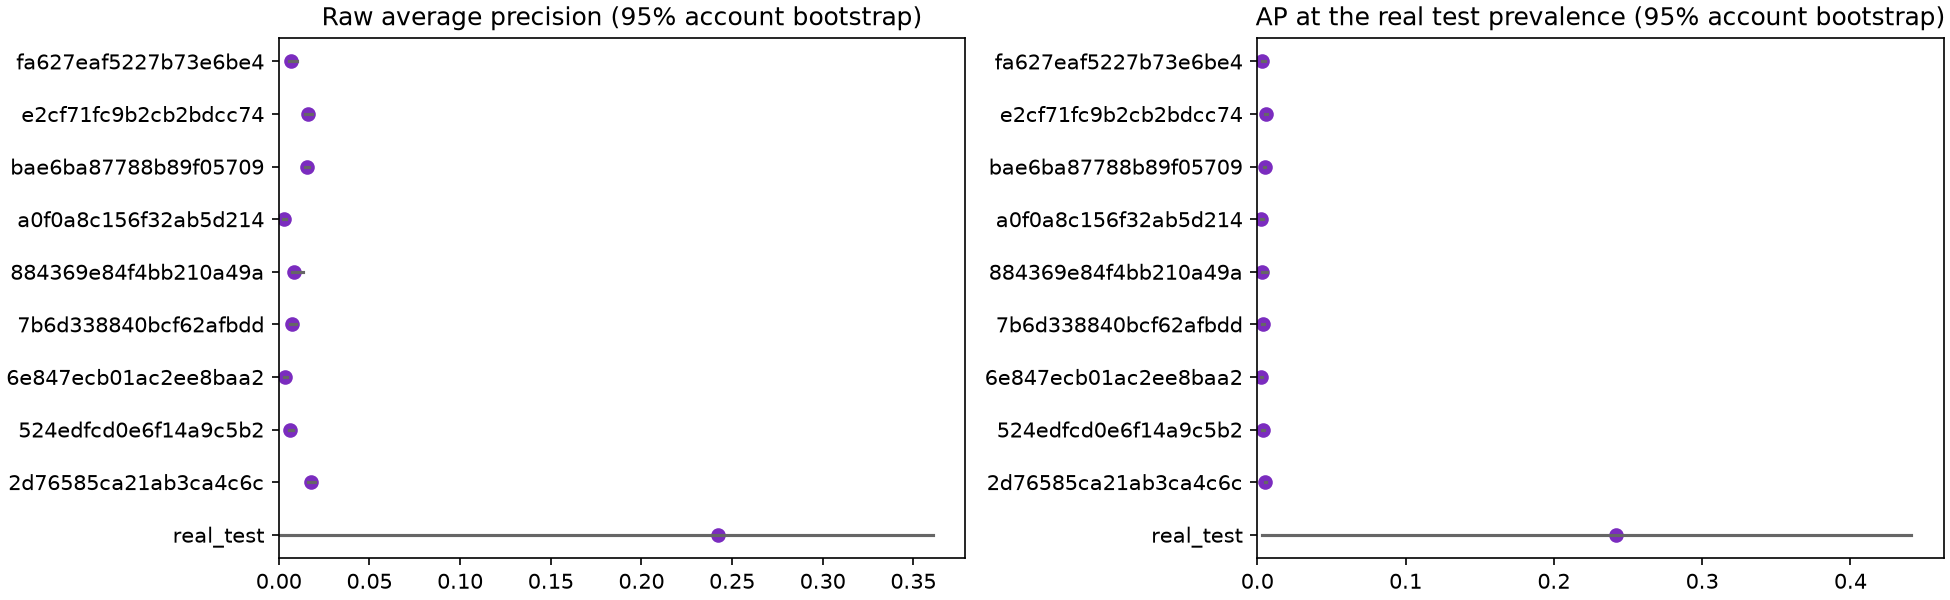

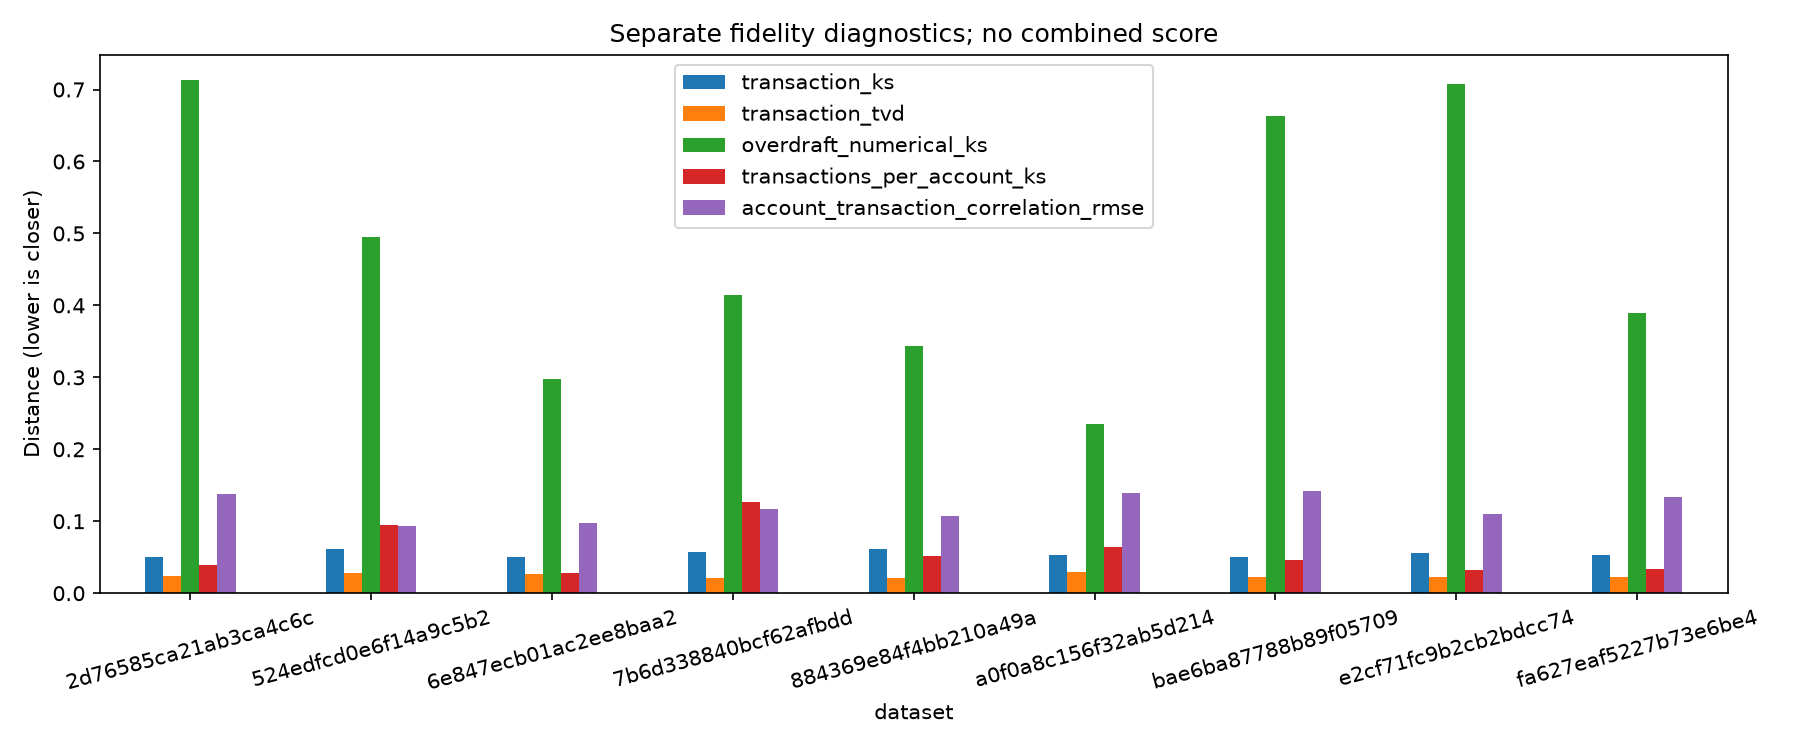

Completed 9 of 9 requested seed/configuration pairs.
Full multi-table quality — separate from overdraft transfer:


,all_table_count,all_edge_count,all_table_numerical_ks,all_table_categorical_tvd,all_cardinality_ks,all_relationship_correlation_rmse,all_min_fk_valid_rate,all_min_pk_unique_rate,multi_parent_correlation_rmse,multi_parent_joint_categorical_tvd,all_undefined_distribution_columns,all_undefined_correlation_pairs
dataset,,,,,,,,,,,,
2d76585ca21ab3ca4c6c,8.0,8.0,0.0938,0.0980,0.0557,NaN,1.0000,1.0,0.0248,0.1570,0.0,2.0
524edfcd0e6f14a9c5b2,8.0,8.0,0.0999,0.0984,0.0561,NaN,1.0000,1.0,0.0230,0.1598,0.0,2.0
6e847ecb01ac2ee8baa2,8.0,8.0,0.1028,0.1062,0.1112,NaN,0.6449,1.0,0.0359,0.1635,0.0,2.0
7b6d338840bcf62afbdd,8.0,8.0,0.0981,0.1139,0.0797,NaN,0.8431,1.0,0.0591,0.1697,0.0,2.0
884369e84f4bb210a49a,8.0,8.0,0.0982,0.0971,0.0716,NaN,0.8795,1.0,0.0332,0.1518,0.0,2.0
a0f0a8c156f32ab5d214,8.0,8.0,0.1159,0.1064,0.0772,NaN,0.8636,1.0,0.0214,0.1613,0.0,2.0
bae6ba87788b89f05709,8.0,8.0,0.1102,0.1002,0.1166,NaN,1.0000,1.0,0.0147,0.1534,0.0,2.0
e2cf71fc9b2cb2bdcc74,8.0,8.0,0.1110,0.1111,0.0867,NaN,1.0000,1.0,0.0445,0.1888,0.0,2.0
fa627eaf5227b73e6be4,8.0,8.0,0.1071,0.1200,0.0680,NaN,0.8514,1.0,0.0215,0.1638,0.0,2.0


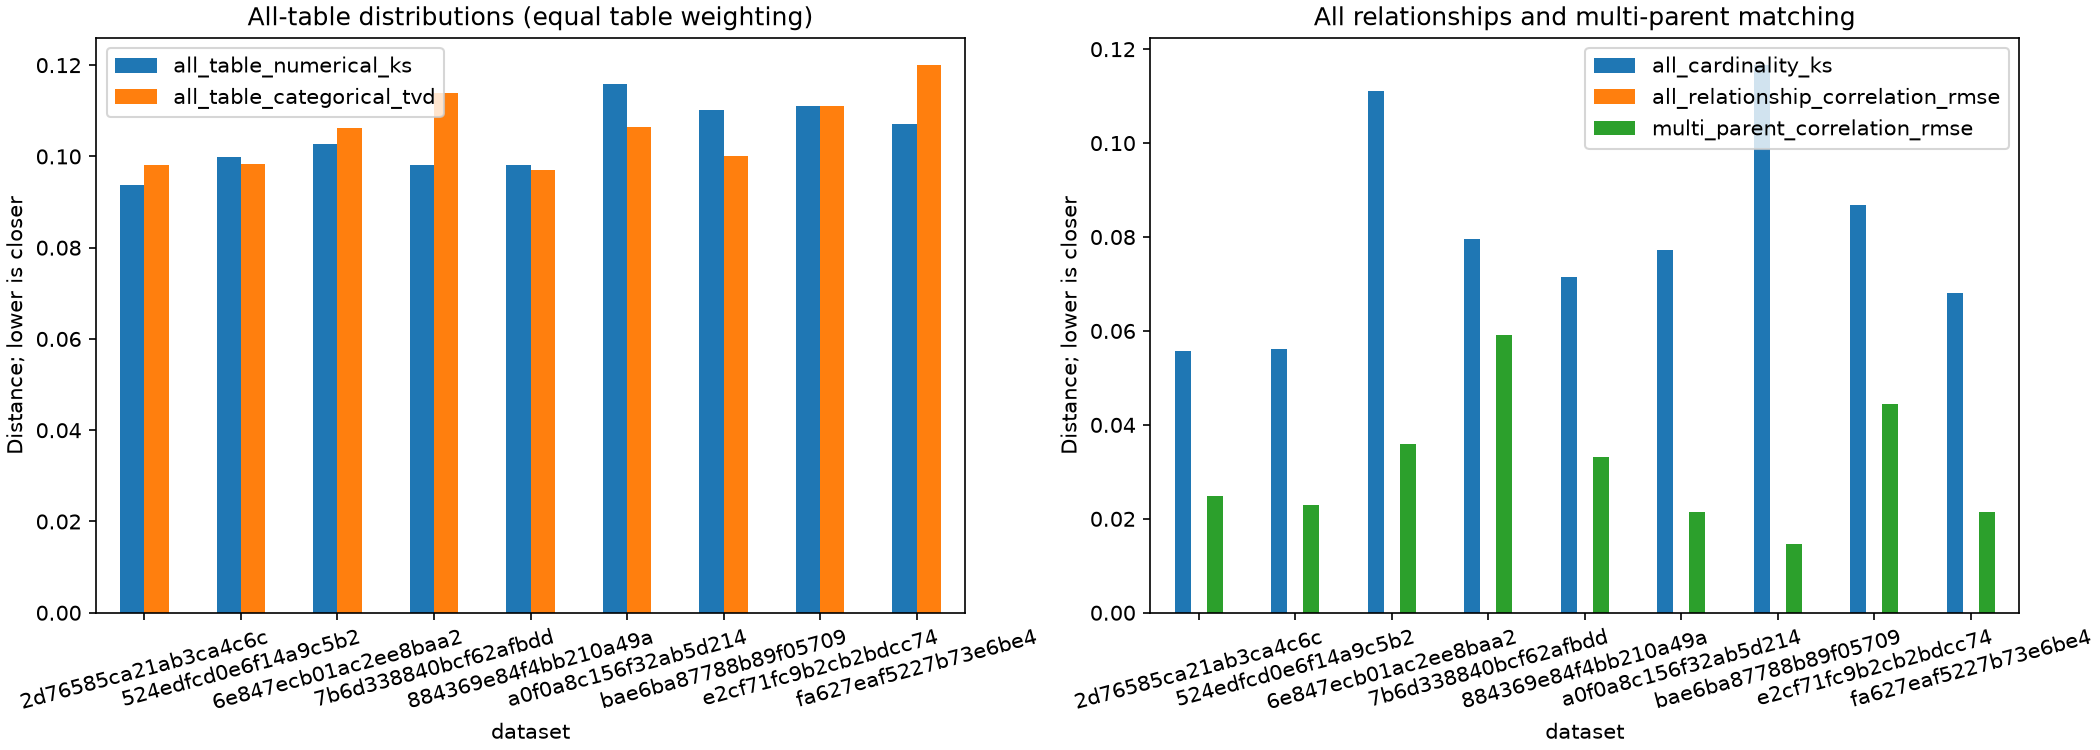

In [10]:
RUN_DIRS = completed_runs(DATA_DIR, EXPERIMENT_ROOT, configs=TRIALS) if DATA_DIR.is_dir() else []
comparison = None
REPORT_DIR = None
if RUN_DIRS:
    comparison, REPORT_DIR = evaluate_saved_runs(DATA_DIR, RUN_DIRS, OUTPUT_ROOT, bootstrap_repetitions=200)
    section, field = PARAMETER.split(".")
    parameter_values = {}
    for run in RUN_DIRS:
        saved = yaml.safe_load((run / "config.yaml").read_text())
        parameter_values[run.name] = str(saved[section][field])
    comparison.insert(0, "parameter_value", pd.Series(parameter_values))
    TRANSFER_AND_QUALITY = [
        "average_precision", "average_precision_low", "average_precision_high",
        "standardized_ap", "overdraft_prevalence", "transaction_ks", "transaction_tvd",
        "overdraft_numerical_ks", "synthetic_transaction_before_account_rate",
    ]
    show(comparison[["parameter_value", *TRANSFER_AND_QUALITY]].round(4))
    print(f"Detailed report: {REPORT_DIR}")
    show(Image(filename=str(REPORT_DIR / "transfer_intervals.png")))
    show(Image(filename=str(REPORT_DIR / "quality_comparison.png")))
    print(f"Completed {len(RUN_DIRS)} of {len(TRIALS)} requested seed/configuration pairs.")
else:
    print("No completed results for this experiment. Start with 01_baseline.ipynb.")

if comparison is not None:
    FULL_TABLE_COLUMNS = [
        "all_table_count", "all_edge_count", "all_table_numerical_ks", "all_table_categorical_tvd",
        "all_cardinality_ks", "all_relationship_correlation_rmse", "all_min_fk_valid_rate",
        "all_min_pk_unique_rate", "multi_parent_correlation_rmse", "multi_parent_joint_categorical_tvd",
        "all_undefined_distribution_columns", "all_undefined_correlation_pairs",
    ]
    print("Full multi-table quality — separate from overdraft transfer:")
    show(comparison.loc[comparison.index != "real_test", FULL_TABLE_COLUMNS].round(4))
    show(Image(filename=str(REPORT_DIR / "multi_table_quality.png")))


## 5. Conclusion — parent weight (2026-11-12)

**Decision: keep 1.0. Reject 0.5 and 2.0. The gains 2.0 showed at training seed 42 did not hold at other training seeds.**

**Two checks were run:**
- **Sampling-seed check:** training seed 42 × sampling seeds 42/43/44. This varies generation only. ([report](../../../results/experiments/transaction_overdraft_from_scratch/fef27de26a023405/comparison.csv))
- **Training-seed check:** training seeds 42/43/44 × sampling seed 42. This retrains every model per seed. ([report](../../../results/experiments/transaction_overdraft_from_scratch/b52d0d6409bd1389/comparison.csv))

### Sampling-seed check (mean ± sd over sampling seeds)

| Parent scale | Standardized AP ↑ | ROC-AUC ↑ | Accounts (real 500) | Transactions (real 117,560) | Cardinality KS ↓ | All-table numerical KS ↓ |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 0.5 | 0.0048 ± 0.0002 | 0.749 ± 0.013 | 750 | 181,854 | 0.102 | 0.103 ± 0.007 |
| **1.0 (baseline)** | 0.0054 ± 0.0003 | 0.763 ± 0.007 | 465 | 114,050 | 0.074 | 0.104 ± 0.012 |
| 2.0 | 0.0052 ± 0.0003 | 0.776 ± 0.014 | 458 | 114,983 | 0.059 | 0.094 ± 0.002 |

### Training-seed check (seed 42 / 43 / 44)

| Parent scale | ROC-AUC ↑ | Standardized AP ↑ | Cardinality KS ↓ | All-table numerical KS ↓ | Transactions (real 117,560) | Before opening ↓ | Orphan cards |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0.5 | 0.755 / 0.646 / 0.545 | 0.0050 / 0.0037 / 0.0027 | 0.117 / 0.080 / 0.077 | 0.110 / 0.098 / 0.116 | 196,501 / 116,619 / 123,513 | 22.5 / 21.7 / 24.6% | 0 / 16 / 12 |
| **1.0 (baseline)** | 0.769 / 0.614 / 0.653 | 0.0056 / 0.0034 / 0.0036 | 0.087 / 0.068 / 0.056 | 0.111 / 0.107 / 0.100 | 114,244 / 100,401 / 103,132 | 20.5 / 23.1 / 16.1% | 0 / 11 / 0 |
| 2.0 | 0.785 / 0.613 / 0.568 | 0.0054 / 0.0035 / 0.0025 | 0.056 / 0.072 / 0.111 | 0.094 / 0.098 / 0.103 | 100,630 / 96,447 / 92,799 | 22.7 / 19.8 / 15.3% | 0 / 10 / 38 |

**Real reference:** test AP 0.2422, ROC-AUC 0.8722; 5.6% of accounts ever overdrawn; 0% of transactions before opening.

- **Retraining moves results more than parent scale does.** Baseline ROC-AUC spans 0.614–0.769 across training seeds (sd 0.081), versus ±0.007 across sampling seeds. The sampling-seed check alone overstated how certain the 2.0 gains were.
- **2.0 does not hold up.** At training seed 44 its ROC-AUC (0.568 vs 0.653) and cardinality KS (0.111 vs 0.056) are worse than the baseline. It generates fewer transactions in every seed and left 38 orphan cards at seed 44. Its only repeatable edge is all-table numerical KS, better in 2 of 3 seeds.
- **0.5 has worse cardinality KS in every seed.** At training seed 42 it also inflated table sizes (+67% transactions).
- **Orphan cards are not a parent-scale effect.** The baseline also produced 11 at seed 43. The cause is a multi-parent matching bug; see [PROGRESS.md](../../docs/PROGRESS.md).
- **No value fixes** overdraft concentration or chronology.

**Next:** none for parent scale. Revisit only after the orphan-card and date-representation fixes, with 3 training seeds.